# Assignment 07 — EC: three-way sentiment of e-commerce review comments with a 5-layer RNN and LSTM

**Dataset:** *Amazon Reviews: Unlocked Mobile Phones* (PromptCloud, Kaggle): 413,840 reviews of about 4,400 phones sold on Amazon, each with a 1–5 star rating and the review text (132 MB CSV).
**Task:** read the text of a review and decide what the customer felt: **negative** (1–2 stars), **neutral** (3 stars) or **positive** (4–5 stars). The neutral class is kept on purpose: a 3-star review is the hardest case for a model that reads words one at a time ("works fine, but..."), and it is exactly where memory could matter.

**Models:** the same architecture four times, {5-layer RNN, 5-layer LSTM} × {Keras, PyTorch}:
word ids → embedding (48-d) → 5 recurrent layers (64 units) → last state → Dense(3) → softmax.
Run IDs: `EC-TF-RNN`, `EC-TF-LSTM`, `EC-PT-RNN`, `EC-PT-LSTM`. Both structures are derived step by step in `00_rnn_lstm_concepts.ipynb`.

## 1. Setup

One seed (7) for Python, NumPy, TensorFlow and PyTorch. Every run uses the same arrays, the same architecture, the same optimizer (Adam, learning rate $10^{-3}$, gradient clipping at norm 1), the same class weights, batch size 256, at most 8 epochs and early stopping (patience 2) on the validation loss, keeping the best epoch.

In [1]:
import os, re, time, json, random, collections, warnings
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss, confusion_matrix
warnings.filterwarnings("ignore")

SEED = 7
random.seed(SEED); np.random.seed(SEED)
DATA = Path("../dataset/ec")
RES = Path("results"); RES.mkdir(parents=True, exist_ok=True)
IMG = Path("../report/images"); IMG.mkdir(parents=True, exist_ok=True)

CLASSES = ["negative", "neutral", "positive"]
VOCAB, MAXLEN, EMB, H, LAYERS, NCLS = 15_000, 120, 48, 64, 5, 3
BATCH, LR, CLIP = 256, 1e-3, 1.0
EPOCHS, PATIENCE = 8, 2
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("results ->", RES.resolve())

results -> E:\CODING\IS_AI\intelligent_system_assignments\assignment_07\notebook\results


### Hyperparameters

| Name | Value | Meaning |
|---|---|---|
| classes | negative (1–2★), neutral (3★), positive (4–5★) | 3-way sentiment |
| vocabulary | 15,000 words | the most frequent words of the **training** reviews; others become `<unk>` |
| sequence length $T$ | 120 tokens | a review longer than 120 words keeps its **last** 120 words |
| embedding | 48 | each word id becomes a learned 48-d vector |
| hidden units $H$ | 64 per layer | |
| layers $L$ | 5 | stacked: layer $l$ reads the states of layer $l-1$ |
| output | Dense(3) + softmax | $P(\text{negative}),P(\text{neutral}),P(\text{positive})$ |
| loss | class-weighted cross-entropy | $-w_{y}\ln p_y$ |
| optimizer | Adam, lr $10^{-3}$, clip-norm 1 | clipping limits exploding gradients |
| batch / epochs | 256 / ≤ 8, early stopping patience 2 | |
| split | stratified 80 / 10 / 10 | |

## 2. Data

Raw columns: product, brand, price, **Rating**, **Reviews** (text), review votes. Steps: drop empty reviews → **drop duplicate texts** (the same review is listed once per phone variant; keeping the copies would put the same text in the training and the test set) → map stars to three classes.

In [2]:
raw = pd.read_csv(DATA / "Amazon_Unlocked_Mobile.csv")
print("raw shape:", raw.shape)
display(raw.head(3))
print("empty reviews:", raw.Reviews.isna().sum(), "| duplicated review texts:", raw.Reviews.duplicated().sum())

raw shape: (413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0


empty reviews: 70 | duplicated review texts: 251349


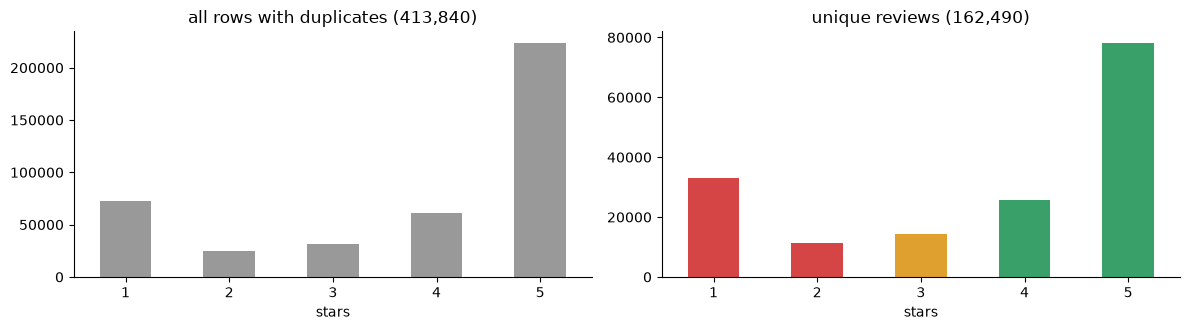

class shares: {'negative': 0.273, 'neutral': 0.088, 'positive': 0.639}


In [3]:
df = raw.dropna(subset=["Reviews"]).drop_duplicates(subset=["Reviews"]).copy()
df["y"] = np.select([df.Rating <= 2, df.Rating == 3], [0, 1], default=2)
df["n_words"] = df.Reviews.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
raw.Rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#999", rot=0, title=f"all rows with duplicates ({len(raw):,})")
df.Rating.value_counts().sort_index().plot.bar(ax=ax[1], color=["#d64545", "#d64545", "#e0a030", "#3aa06a", "#3aa06a"], rot=0, title=f"unique reviews ({len(df):,})")
for a in ax: a.set_xlabel("stars")
plt.tight_layout(); plt.savefig(IMG / "EC_ratings.png", bbox_inches="tight"); plt.show()
share = df.y.value_counts(normalize=True).sort_index()
print("class shares:", {c: round(float(share[i]), 3) for i, c in enumerate(CLASSES)})

**Reading the plot.** Five stars dominates and one star comes second: people write when they are delighted or angry. After removing duplicate texts about 64 % of the reviews are positive, 27 % negative and only 9 % neutral. Two consequences: a model that always says "positive" is right 64 % of the time, so accuracy alone is misleading; and the neutral class is small, so it needs special care in the loss (weights, §3) and in the metrics (macro-F1 gives each class the same say).

### Review length

A recurrent network reads one word per step, so the number of words in a review is the number of steps.

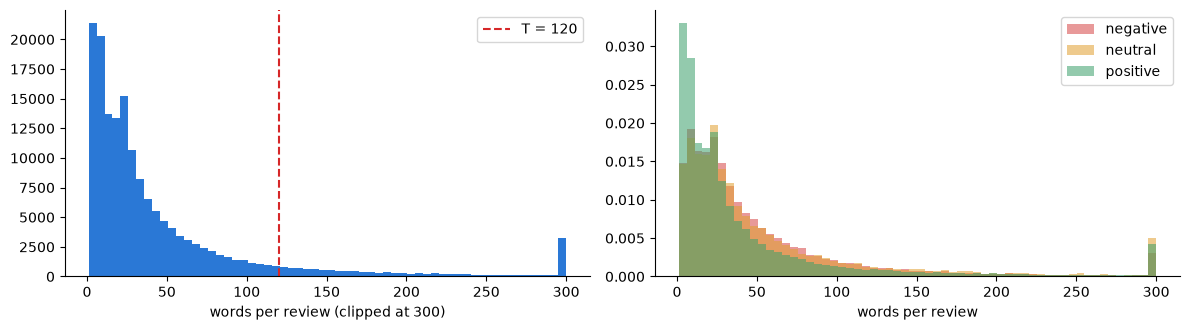

           50%   75%     max
y                           
negative  31.0  62.0  4815.0
neutral   31.0  65.0  3014.0
positive  21.0  46.0  5313.0
share of reviews with <= 120 words: 0.910


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(df.n_words.clip(upper=300), bins=60, color="#2a78d6"); ax[0].axvline(MAXLEN, c="C3", ls="--", label=f"T = {MAXLEN}")
ax[0].set_xlabel("words per review (clipped at 300)"); ax[0].legend()
for y, name, c in [(0, "negative", "#d64545"), (1, "neutral", "#e0a030"), (2, "positive", "#3aa06a")]:
    ax[1].hist(df.n_words[df.y == y].clip(upper=300), bins=60, alpha=0.55, density=True, color=c, label=name)
ax[1].set_xlabel("words per review"); ax[1].legend(); plt.tight_layout(); plt.savefig(IMG / "EC_length.png", bbox_inches="tight"); plt.show()
print(df.groupby("y").n_words.describe()[["50%", "75%", "max"]].rename(index=dict(enumerate(CLASSES))))
print(f"share of reviews with <= {MAXLEN} words: {(df.n_words <= MAXLEN).mean():.3f}")

Median length rises from positive to neutral to negative: the less happy the customer, the more there is to explain. The evidence for "negative" or "neutral" is therefore often spread over many words, a case where a model's memory matters.

### Which words separate the classes?

Before any neural network: for each word, the share of negative reviews containing it minus the share of positive reviews containing it.

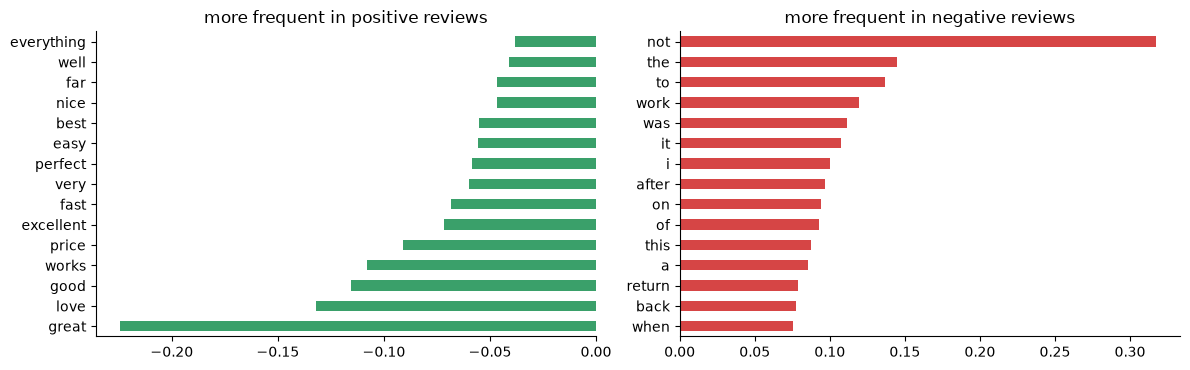

In [5]:
def tokenize(text):
    """lower-case, keep letters, digits and apostrophes: "Don't buy!!" -> ["don't", "buy"]"""
    return re.findall(r"[a-z0-9']+", text.lower())

pos_c, neg_c = collections.Counter(), collections.Counter()
sub = df.sample(min(60_000, len(df)), random_state=SEED)
for text, y in zip(sub.Reviews.values, sub.y.values):
    if y == 2: pos_c.update(set(tokenize(text)))
    elif y == 0: neg_c.update(set(tokenize(text)))
n_pos, n_neg = (sub.y == 2).sum(), (sub.y == 0).sum()
words = [w for w, c in (pos_c + neg_c).most_common(3000)]
diff = pd.Series({w: neg_c[w] / n_neg - pos_c[w] / n_pos for w in words}).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
diff.head(15).plot.barh(ax=ax[0], color="#3aa06a", title="more frequent in positive reviews")
diff.tail(15).plot.barh(ax=ax[1], color="#d64545", title="more frequent in negative reviews")
plt.tight_layout(); plt.savefig(IMG / "EC_words.png", bbox_inches="tight"); plt.show()

## 3. From text to numbers, step by step

A network cannot read text. The review goes through four steps, shown below on one real review:

1. **tokenize**: split into lower-case words;
2. **vocabulary**: give the 15,000 most frequent training words an id (1 = `<unk>` for unknown words, 0 = padding);
3. **encode**: replace each word by its id;
4. **pad / truncate** to $T=120$. A shorter review gets zeros **in front** (pre-padding), so the last steps the network reads are real words and the final state $h_T$ has just seen the text. A longer review keeps its **last** 120 words: people state their verdict at the end ("so I returned it"), and the final state is the one that is classified.

The data are split **before** the vocabulary is built (80 % train, 10 % validation, 10 % test, stratified by class), so the vocabulary never sees validation or test words.

**Class weights.** With 64 / 27 / 9 % of the reviews, plain cross-entropy would let the network ignore the neutral class. Each training review is weighted by $w_c\propto 1/\sqrt{\text{share}_c}$, normalised so that the average weight over the training set is 1. The square root is a compromise: full inverse-frequency weights would make a neutral review count seven times as much as a positive one and make training noisy. The weights only change the **training** loss; validation loss, early stopping and all metrics are unweighted, so every run is judged on the real class mix.

In [6]:
idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=0.20, stratify=df.y, random_state=SEED)
i_va, i_te = train_test_split(i_tmp, test_size=0.50, stratify=df.y.values[i_tmp], random_state=SEED)
texts, y_all = df.Reviews.values, df.y.values.astype("int32")
print(f"train {len(i_tr):,} | validation {len(i_va):,} | test {len(i_te):,}")

counts = collections.Counter(w for t in texts[i_tr] for w in tokenize(t))
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(VOCAB - 2)]
stoi = {w: i for i, w in enumerate(itos)}
coverage = sum(counts[w] for w in itos[2:]) / sum(counts.values())
print(f"{len(counts):,} distinct training words; the top {VOCAB:,} cover {coverage:.1%} of all word occurrences")

def encode(text):
    ids = [stoi.get(w, 1) for w in tokenize(text)][-MAXLEN:]          # truncate: keep the LAST T words
    return [0] * (MAXLEN - len(ids)) + ids                             # pre-pad with 0

ex = texts[i_tr][3]
print("\n1. review   :", ex[:160])
print("2. tokens   :", tokenize(ex)[:14])
print("3. ids      :", [stoi.get(w, 1) for w in tokenize(ex)][:14])
print("4. padded   :", encode(ex)[:6], "...", encode(ex)[-8:], f"(length {len(encode(ex))})")
print("   decoded  :", " ".join(itos[i] for i in encode(ex) if i)[:160])

train 129,992 | validation 16,249 | test 16,249


62,418 distinct training words; the top 15,000 cover 99.0% of all word occurrences

1. review   : This phone is garbage. I've had it for less than three months and it's always having problems. Constantly freezing, kicking me out of apps, and dying way above 
2. tokens   : ['this', 'phone', 'is', 'garbage', "i've", 'had', 'it', 'for', 'less', 'than', 'three', 'months', 'and', "it's"]
3. ids      : [10, 6, 9, 1385, 133, 28, 4, 11, 301, 60, 528, 171, 5, 47]
4. padded   : [0, 0, 0, 0, 0, 0] ... [2654, 11, 10, 132, 5, 17, 26, 304] (length 120)
   decoded  : this phone is garbage i've had it for less than three months and it's always having problems constantly freezing kicking me out of apps and dying way above 0 ye


In [7]:
X_all = np.array([encode(t) for t in texts], dtype="int32")
Xtr, Xva, Xte = X_all[i_tr], X_all[i_va], X_all[i_te]
ytr, yva, yte = y_all[i_tr], y_all[i_va], y_all[i_te]
print("X_train:", Xtr.shape, "(reviews, T)  y_train:", ytr.shape)
print("share of <unk> among real tokens:", f"{(Xtr == 1).sum() / (Xtr > 0).sum():.3%}")

freq = np.bincount(ytr, minlength=NCLS) / len(ytr)
cw = 1 / np.sqrt(freq); cw = cw / (cw * freq).sum()               # mean weight over the training set = 1
CW = {i: float(w) for i, w in enumerate(cw)}
print("train class shares:", dict(zip(CLASSES, freq.round(3))), "\nclass weights    :", dict(zip(CLASSES, cw.round(3))))

X_train: (129992, 120) (reviews, T)  y_train: (129992,)
share of <unk> among real tokens: 1.021%
train class shares: {'negative': np.float64(0.273), 'neutral': np.float64(0.088), 'positive': np.float64(0.639)} 
class weights    : {'negative': np.float64(1.182), 'neutral': np.float64(2.077), 'positive': np.float64(0.773)}


**Shapes through the network** for a batch of 256 reviews:
`(256, 120)` word ids → embedding → `(256, 120, 48)` → layer 1 `(256, 120, 64)` → layers 2–5, each `(256, 120, 64)` → last step of layer 5 `(256, 64)` → Dense `(256, 3)` → softmax → three probabilities.

### Shared evaluation helpers

Every run goes through `finalize`: class probabilities on the test set, predicted class = the largest probability, then accuracy, F1 of each class, macro-F1 (the plain mean of the three F1 scores, so the small neutral class counts as much as the large positive one), one-vs-rest ROC-AUC averaged over classes, and the log-loss (the unweighted cross-entropy: it also judges how well calibrated the probabilities are).

In [8]:
RUNS = {}

def metrics(y, P):
    P = np.asarray(P, dtype="float64"); P = P / P.sum(1, keepdims=True)
    yhat = P.argmax(1); f1 = f1_score(y, yhat, average=None, labels=[0, 1, 2])
    return dict(accuracy=float(accuracy_score(y, yhat)), f1_macro=float(f1.mean()), f1_negative=float(f1[0]), f1_neutral=float(f1[1]),
                f1_positive=float(f1[2]), roc_auc=float(roc_auc_score(y, P, multi_class="ovr", average="macro")),
                logloss=float(log_loss(y, P, labels=[0, 1, 2])))

def finalize(run_id, P_test, history, params, sec_epoch, total_s):
    rec = dict(run_id=run_id, params=int(params), sec_per_epoch=round(sec_epoch, 2), train_seconds=round(total_s, 1),
               epochs=len(history["loss"]), best_epoch=int(np.argmin(history["val_loss"]) + 1),
               history=history, **metrics(yte, P_test))
    RUNS[run_id] = {**rec, "p_test": np.asarray(P_test, dtype="float64")}
    json.dump(rec, open(RES / f"{run_id}.json", "w"), indent=1)
    print(f"{run_id}: acc {rec['accuracy']:.4f}  F1-macro {rec['f1_macro']:.4f}  (neg {rec['f1_negative']:.3f} / neu {rec['f1_neutral']:.3f} / pos {rec['f1_positive']:.3f})  "
          f"AUC {rec['roc_auc']:.4f}  epochs {rec['epochs']} (best {rec['best_epoch']})  {sec_epoch:.0f} s/epoch")
    return rec

def rnn_params(F, H, L, nb=1):  return F * H + H * H + nb * H + (L - 1) * (2 * H * H + nb * H)
def lstm_params(F, H, L, nb=1): return 4 * rnn_params(F, H, L, nb)
HEAD = H * NCLS + NCLS
EXPECTED = {"RNN": VOCAB * EMB + rnn_params(EMB, H, LAYERS) + HEAD, "LSTM": VOCAB * EMB + lstm_params(EMB, H, LAYERS) + HEAD}
print("expected parameters (Keras-style, one bias):", {k: f"{v:,}" for k, v in EXPECTED.items()})

expected parameters (Keras-style, one bias): {'RNN': '760,451', 'LSTM': '881,219'}


## 4. Baselines

- **Class prior**: always predict the training class shares (so always "positive"). It sets the floor for accuracy and gives the log-loss of a model that knows nothing about the text.
- **TF-IDF + logistic regression**: a strong classical model that ignores word order. Each review becomes a weighted bag of words and word pairs, and a multinomial linear model scores it, trained with the same class weights as the networks. If a recurrent network cannot beat it, the network's ability to read order is not being used.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
BASE, BASE_P = {}, {}
BASE_P["class prior"] = np.tile(freq, (len(yte), 1))
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200_000, sublinear_tf=True)
lr = LogisticRegression(max_iter=1000, C=4, class_weight=CW).fit(tfidf.fit_transform(texts[i_tr]), ytr)
BASE_P["tfidf_logreg"] = lr.predict_proba(tfidf.transform(texts[i_te]))
for k, P in BASE_P.items(): BASE[k] = metrics(yte, P)
print(f"TF-IDF + logistic regression trained in {time.time() - t0:.0f} s")
display(pd.DataFrame(BASE).T.round(4))

TF-IDF + logistic regression trained in 39 s


,accuracy,f1_macro,f1_negative,f1_neutral,f1_positive,roc_auc,logloss
class prior,0.6387,0.2598,0.0000,0.0000,0.7795,0.5000,0.8552
tfidf_logreg,0.8498,0.6879,0.8341,0.3054,0.9244,0.9155,0.3958


## 5. Keras — runs `EC-TF-RNN`, `EC-TF-LSTM`

In Keras the 5-layer network is a list of layers: `Embedding` → four recurrent layers with `return_sequences=True` (they hand the whole sequence of states to the next layer) → a fifth with `return_sequences=False` (it returns only its last state $h^{(5)}_T$) → `Dense(3, softmax)`.
`SimpleRNN` computes $h_t=\tanh(x_tW+h_{t-1}U+b)$; `LSTM` adds the gates. Keras defaults: Glorot-uniform input weights, orthogonal recurrent weights, zero biases, LSTM forget-gate bias 1. `model.fit(..., class_weight=CW)` runs the training loop with the weighted loss.

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

def build_keras(kind):
    cell = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM}[kind]
    stack = [layers.Input((MAXLEN,), dtype="int32"), layers.Embedding(VOCAB, EMB)]
    stack += [cell(H, return_sequences=(l < LAYERS - 1)) for l in range(LAYERS)]
    stack += [layers.Dense(NCLS, activation="softmax")]
    m = keras.Sequential(stack, name=f"keras_{kind}")
    m.compile(optimizer=keras.optimizers.Adam(LR, clipnorm=CLIP), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self.t)

def run_keras(kind):
    tf.keras.utils.set_random_seed(SEED)
    m = build_keras(kind)
    assert m.count_params() == EXPECTED[kind], (m.count_params(), EXPECTED[kind])
    timer = EpochTimer(); t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH, verbose=2, class_weight=CW,
              callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True), timer])
    P = m.predict(Xte, batch_size=1024, verbose=0)
    hist = {"loss": h.history["loss"], "val_loss": h.history["val_loss"], "acc": h.history["accuracy"], "val_acc": h.history["val_accuracy"]}
    return finalize(f"EC-TF-{kind}", P, hist, m.count_params(), float(np.median(timer.times[1:] or timer.times)), time.time() - t0)

build_keras("RNN").summary()

TensorFlow 2.21.0 | GPUs: []


Model: "keras_RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 120, 48)        │       720,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 120, 64)        │         7,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 120, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 120, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 120, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 760,451 (2.90 MB)

 Trainable params: 760,451 (2.90 MB)

 Non-trainable params: 0 (0.00 B)

The count matches the formula of the concepts notebook: embedding $15{,}000\cdot48=720{,}000$; layer 1 $48\cdot64+64\cdot64+64=7{,}232$; layers 2–5 $2\cdot64^2+64=8{,}256$ each; head $64\cdot3+3=195$. The embedding table holds 95 % of the RNN's parameters and 82 % of the LSTM's; the five recurrent layers hold 40,256 (RNN) or 161,024 (LSTM).

In [11]:
run_keras("RNN");

Epoch 1/8


508/508 - 73s - 144ms/step - accuracy: 0.7493 - loss: 0.7939 - val_accuracy: 0.8289 - val_loss: 0.5092


Epoch 2/8


508/508 - 69s - 136ms/step - accuracy: 0.8247 - loss: 0.6185 - val_accuracy: 0.8301 - val_loss: 0.4796


Epoch 3/8


508/508 - 70s - 137ms/step - accuracy: 0.8297 - loss: 0.5914 - val_accuracy: 0.8195 - val_loss: 0.4838


Epoch 4/8


508/508 - 70s - 138ms/step - accuracy: 0.8298 - loss: 0.5775 - val_accuracy: 0.8159 - val_loss: 0.5266


EC-TF-RNN: acc 0.8290  F1-macro 0.6140  (neg 0.800 / neu 0.133 / pos 0.909)  AUC 0.8857  epochs 4 (best 2)  70 s/epoch


In [12]:
run_keras("LSTM");

Epoch 1/8


508/508 - 282s - 556ms/step - accuracy: 0.7922 - loss: 0.6856 - val_accuracy: 0.8306 - val_loss: 0.4486


Epoch 2/8


508/508 - 278s - 547ms/step - accuracy: 0.8353 - loss: 0.5285 - val_accuracy: 0.8359 - val_loss: 0.4296


Epoch 3/8


508/508 - 278s - 548ms/step - accuracy: 0.8471 - loss: 0.4828 - val_accuracy: 0.8285 - val_loss: 0.4460


Epoch 4/8


508/508 - 279s - 549ms/step - accuracy: 0.8545 - loss: 0.4570 - val_accuracy: 0.8212 - val_loss: 0.4745


EC-TF-LSTM: acc 0.8342  F1-macro 0.6823  (neg 0.826 / neu 0.309 / pos 0.912)  AUC 0.9096  epochs 4 (best 2)  278 s/epoch


## 6. PyTorch — runs `EC-PT-RNN`, `EC-PT-LSTM`

PyTorch writes the same network as a class: `nn.Embedding` → `nn.RNN(48, 64, num_layers=5, batch_first=True)` (or `nn.LSTM`) → last step of the top layer → `nn.Linear(64, 3)`. One call with `num_layers=5` is the whole stack $f^{(5)}\circ\dots\circ f^{(1)}$. The training loop is written by hand: `zero_grad → forward → loss → backward → clip → step`. The class weights enter as `loss_i · w[y_i]`, averaged over the batch, which is what Keras's `class_weight` does.

For a fair start the PyTorch weights get Keras's initialisation (Glorot-uniform input weights, orthogonal recurrent weights, zero biases, LSTM forget bias 1, embedding uniform in ±0.05). PyTorch keeps **two** bias vectors per layer (`bias_ih`, `bias_hh`), so it has $5\cdot64=320$ (RNN) or $5\cdot256=1{,}280$ (LSTM) more parameters, all starting at zero; their sum is Keras's single bias.

In [13]:
import torch, torch.nn as nn, torch.nn.functional as Fn
torch.manual_seed(SEED)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEV)
CW_T = torch.tensor(cw, dtype=torch.float32, device=DEV)

class TorchSentiment(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, EMB)
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM}[kind](EMB, H, num_layers=LAYERS, batch_first=True)
        self.head = nn.Linear(H, NCLS)
        nn.init.uniform_(self.emb.weight, -0.05, 0.05)
        for name, p in self.rnn.named_parameters():                # Keras-style initialisation
            blocks = 4 if kind == "LSTM" else 1
            if name.startswith("weight_ih"):
                for blk in p.data.chunk(blocks): nn.init.xavier_uniform_(blk)
            elif name.startswith("weight_hh"):
                for blk in p.data.chunk(blocks): nn.init.orthogonal_(blk)
            else:
                nn.init.zeros_(p)
                if kind == "LSTM" and name.startswith("bias_ih"): p.data[H:2 * H] = 1.0   # forget gate
        nn.init.xavier_uniform_(self.head.weight); nn.init.zeros_(self.head.bias)
    def forward(self, x):                      # x: (B, T) word ids
        out, _ = self.rnn(self.emb(x))         # out: (B, T, H), states of the top layer
        return self.head(out[:, -1])           # logits (B, 3) from h^(5)_T

def predict_torch(model, X, bs=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(torch.softmax(model(torch.from_numpy(X[i:i + bs]).long().to(DEV)), 1).cpu().numpy())
    return np.concatenate(out)

def run_torch(kind):
    torch.manual_seed(SEED)
    m = TorchSentiment(kind).to(DEV)
    n = sum(p.numel() for p in m.parameters()); extra = LAYERS * H * (4 if kind == "LSTM" else 1)
    assert n == EXPECTED[kind] + extra, (n, EXPECTED[kind], extra)
    opt = torch.optim.Adam(m.parameters(), lr=LR, eps=1e-7)
    Xt, yt = torch.from_numpy(Xtr).long(), torch.from_numpy(ytr).long()
    Xv, yv = torch.from_numpy(Xva).long().to(DEV), torch.from_numpy(yva).long().to(DEV)
    hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}; times = []; best, best_state, wait = np.inf, None, 0
    g = torch.Generator().manual_seed(SEED); t0 = time.time()
    for ep in range(EPOCHS):
        m.train(); te = time.time(); tot, correct = 0.0, 0
        for b in torch.randperm(len(Xt), generator=g).split(BATCH):
            xb, yb = Xt[b].to(DEV), yt[b].to(DEV)
            logit = m(xb); per = Fn.cross_entropy(logit, yb, reduction="none")
            loss = (per * CW_T[yb]).mean()                                  # class-weighted, averaged over the batch
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), CLIP); opt.step()
            tot += loss.item() * len(b); correct += (logit.argmax(1) == yb).sum().item()
        m.eval()
        with torch.no_grad():
            vl, vc = 0.0, 0
            for i in range(0, len(Xv), 1024):
                lo = m(Xv[i:i + 1024]); vl += Fn.cross_entropy(lo, yv[i:i + 1024], reduction="sum").item(); vc += (lo.argmax(1) == yv[i:i + 1024]).sum().item()
        times.append(time.time() - te)
        hist["loss"].append(tot / len(Xt)); hist["val_loss"].append(vl / len(Xv)); hist["acc"].append(correct / len(Xt)); hist["val_acc"].append(vc / len(Xv))
        print(f"epoch {ep + 1}: loss {hist['loss'][-1]:.4f}  val_loss {hist['val_loss'][-1]:.4f}  val_acc {hist['val_acc'][-1]:.4f}  {times[-1]:.0f}s")
        if hist["val_loss"][-1] < best - 1e-4:
            best, wait = hist["val_loss"][-1], 0; best_state = {k: v.detach().clone() for k, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE: break
    m.load_state_dict(best_state)
    return finalize(f"EC-PT-{kind}", predict_torch(m, Xte), hist, n, float(np.median(times[1:] or times)), time.time() - t0)

print(TorchSentiment("LSTM"))

PyTorch 2.14.1+cpu | device: cpu
TorchSentiment(
  (emb): Embedding(15000, 48)
  (rnn): LSTM(48, 64, num_layers=5, batch_first=True)
  (head): Linear(in_features=64, out_features=3, bias=True)
)


In [14]:
run_torch("RNN");

epoch 1: loss 0.7578  val_loss 0.5350  val_acc 0.8091  97s


epoch 2: loss 0.6277  val_loss 0.4767  val_acc 0.8310  117s


epoch 3: loss 0.6003  val_loss 0.4851  val_acc 0.8267  143s


epoch 4: loss 0.5795  val_loss 0.4847  val_acc 0.8170  206s


EC-PT-RNN: acc 0.8302  F1-macro 0.6047  (neg 0.803 / neu 0.102 / pos 0.909)  AUC 0.8796  epochs 4 (best 2)  143 s/epoch


In [15]:
run_torch("LSTM");

epoch 1: loss 0.6909  val_loss 0.4805  val_acc 0.8117  183s


epoch 2: loss 0.5293  val_loss 0.4597  val_acc 0.8112  183s


epoch 3: loss 0.4788  val_loss 0.4416  val_acc 0.8146  188s


epoch 4: loss 0.4416  val_loss 0.4306  val_acc 0.8297  188s


epoch 5: loss 0.4094  val_loss 0.4464  val_acc 0.8207  190s


epoch 6: loss 0.3791  val_loss 0.4626  val_acc 0.8202  190s


EC-PT-LSTM: acc 0.8289  F1-macro 0.6954  (neg 0.824 / neu 0.350 / pos 0.912)  AUC 0.9131  epochs 6 (best 4)  188 s/epoch


## 7. Comparison

All four runs and the two baselines on the same test reviews.

In [16]:
cols = ["accuracy", "f1_macro", "f1_negative", "f1_neutral", "f1_positive", "roc_auc", "logloss", "params", "sec_per_epoch", "epochs", "best_epoch"]
rows = [{"run": k, **{m: v[m] for m in cols}} for k, v in RUNS.items()]
rows += [{"run": f"baseline: {k}", **v} for k, v in BASE.items()]
table = pd.DataFrame(rows).set_index("run")
table.to_csv(RES / "EC_comparison.csv")
display(table.round(4))

,accuracy,f1_macro,f1_negative,f1_neutral,f1_positive,roc_auc,logloss,params,sec_per_epoch,epochs,best_epoch
run,,,,,,,,,,,
EC-TF-RNN,0.8290,0.6140,0.8001,0.1331,0.9090,0.8857,0.4785,760451.0,69.73,4.0,2.0
EC-TF-LSTM,0.8342,0.6823,0.8260,0.3091,0.9120,0.9096,0.4359,881219.0,278.44,4.0,2.0
EC-PT-RNN,0.8302,0.6047,0.8034,0.1016,0.9092,0.8796,0.4771,760771.0,143.43,4.0,2.0
EC-PT-LSTM,0.8289,0.6954,0.8239,0.3500,0.9123,0.9131,0.4322,882499.0,188.24,6.0,4.0
baseline: class prior,0.6387,0.2598,0.0000,0.0000,0.7795,0.5000,0.8552,NaN,NaN,NaN,NaN
baseline: tfidf_logreg,0.8498,0.6879,0.8341,0.3054,0.9244,0.9155,0.3958,NaN,NaN,NaN,NaN


### Learning curves

Training loss (weighted) and validation loss (unweighted) per epoch. A validation loss that rises while the training loss falls means overfitting; early stopping keeps the epoch with the lowest validation loss.

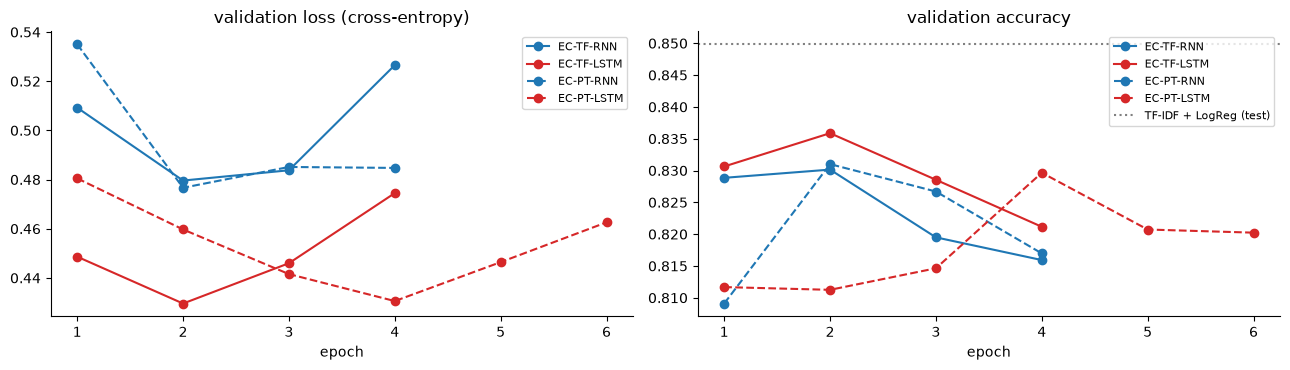

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for k, v in RUNS.items():
    ls = "-" if "-TF-" in k else "--"; c = "C0" if k.endswith("RNN") else "C3"
    ax[0].plot(range(1, len(v["history"]["val_loss"]) + 1), v["history"]["val_loss"], ls, c=c, marker="o", label=k)
    ax[1].plot(range(1, len(v["history"]["val_acc"]) + 1), v["history"]["val_acc"], ls, c=c, marker="o", label=k)
ax[1].axhline(BASE["tfidf_logreg"]["accuracy"], c="gray", ls=":", label="TF-IDF + LogReg (test)")
ax[0].set_title("validation loss (cross-entropy)"); ax[1].set_title("validation accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "EC_curves.png", bbox_inches="tight"); plt.show()

### Confusion matrices

Rows = true class, columns = predicted class, each row divided by its total, so a cell is the share of that true class sent to that prediction (the diagonal is the per-class recall). The neutral row is the one to watch.

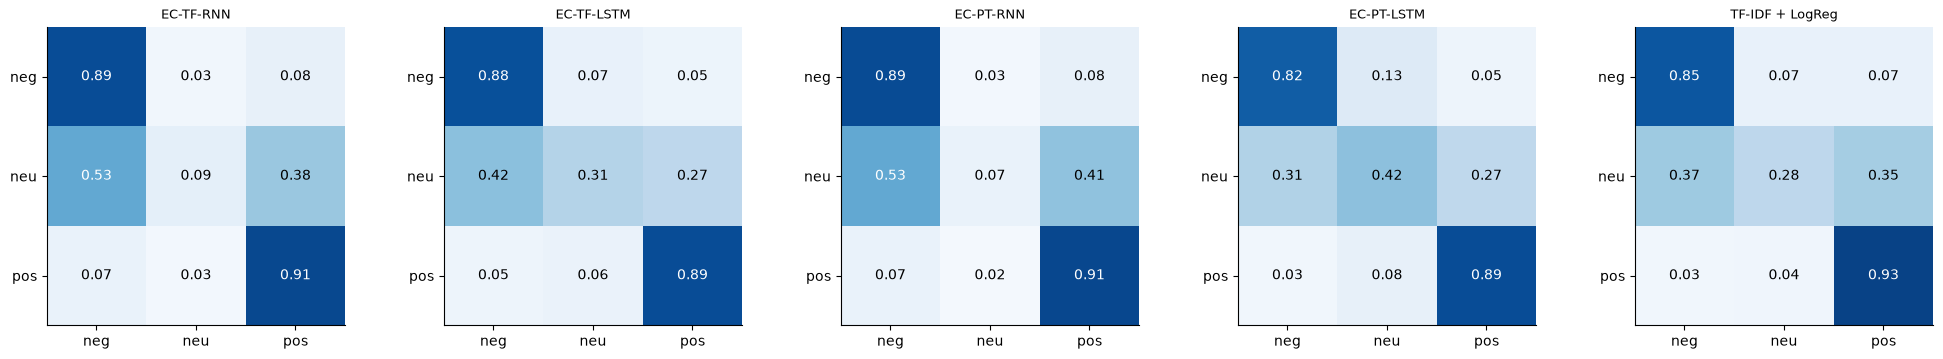

In [18]:
fig, ax = plt.subplots(1, len(RUNS) + 1, figsize=(4 * (len(RUNS) + 1), 3.6))
for a, (k, v) in zip(ax, list(RUNS.items()) + [("TF-IDF + LogReg", {"p_test": BASE_P["tfidf_logreg"]})]):
    cm = confusion_matrix(yte, v["p_test"].argmax(1), normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for (i, j), n in np.ndenumerate(cm): a.text(j, i, f"{n:.2f}", ha="center", va="center", color="white" if n > 0.5 else "black")
    a.set_xticks(range(3), ["neg", "neu", "pos"]); a.set_yticks(range(3), ["neg", "neu", "pos"]); a.set_title(k, fontsize=9)
plt.tight_layout(); plt.savefig(IMG / "EC_confusion.png", bbox_inches="tight"); plt.show()

### Do the models respect the order of the stars?

The networks were trained with three classes and never saw the 1/2 or 4/5 distinction. If they learned a real scale of satisfaction, a sentiment score $s=P(\text{positive})-P(\text{negative})$ should still rise steadily from 1 star to 5 stars. The table shows the mean score on the test reviews of each star level.

,EC-TF-RNN,EC-TF-LSTM,EC-PT-RNN,EC-PT-LSTM,TF-IDF + LogReg,reviews
1,-0.657,-0.770,-0.668,-0.721,-0.739,3317
2,-0.456,-0.527,-0.457,-0.449,-0.454,1118
3,-0.081,-0.105,-0.056,-0.036,-0.005,1436
4,0.540,0.557,0.553,0.596,0.630,2566
5,0.785,0.842,0.792,0.853,0.867,7812


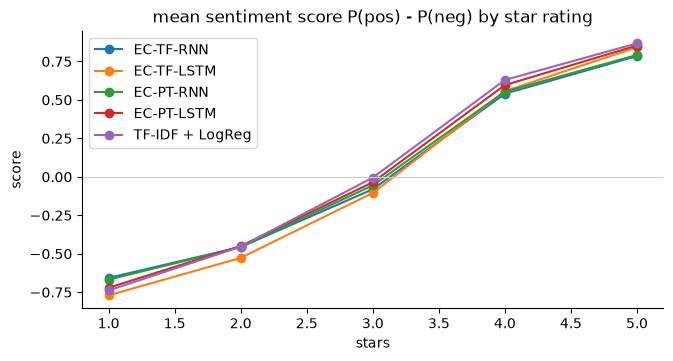

In [19]:
stars = df.Rating.values[i_te]
score = pd.DataFrame({k: pd.Series(v["p_test"][:, 2] - v["p_test"][:, 0]).groupby(stars).mean() for k, v in RUNS.items()})
score["TF-IDF + LogReg"] = pd.Series(BASE_P["tfidf_logreg"][:, 2] - BASE_P["tfidf_logreg"][:, 0]).groupby(stars).mean()
score["reviews"] = pd.Series(stars).value_counts().sort_index().values
score.to_csv(RES / "EC_stars.csv")
display(score.round(3))
score.drop(columns="reviews").plot(marker="o", figsize=(7.5, 3.6), title="mean sentiment score P(pos) - P(neg) by star rating")
plt.xlabel("stars"); plt.ylabel("score"); plt.axhline(0, c="#ccc", lw=0.8); plt.savefig(IMG / "EC_stars.png", bbox_inches="tight"); plt.show()

### Does the LSTM read long reviews better?

Accuracy by review length. If the RNN loses information over many steps (the vanishing gradient of the concepts notebook), its accuracy should drop more on long reviews than the LSTM's. Remember the pre-padding: for a 10-word review the first 110 steps are padding and the real words come last.

,EC-TF-RNN,EC-TF-LSTM,EC-PT-RNN,EC-PT-LSTM,TF-IDF + LogReg,reviews
1-10,0.872,0.886,0.873,0.882,0.880,4159
11-20,0.826,0.838,0.835,0.845,0.851,2616
21-40,0.827,0.830,0.834,0.834,0.850,4130
41-80,0.806,0.804,0.806,0.790,0.824,2852
81-120,0.807,0.805,0.802,0.782,0.819,1053
>120 (cut),0.776,0.771,0.755,0.742,0.837,1439


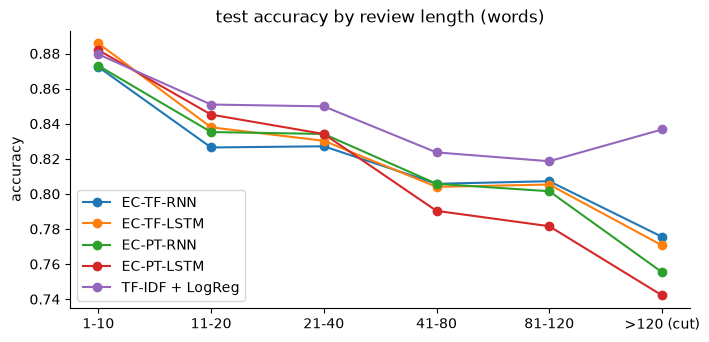

In [20]:
n_te = df.n_words.values[i_te]
bins = [0, 10, 20, 40, 80, 120, 10_000]; labels = ["1-10", "11-20", "21-40", "41-80", "81-120", ">120 (cut)"]
bucket = pd.cut(n_te, bins, labels=labels)
acc_len = pd.DataFrame({k: pd.Series(v["p_test"].argmax(1) == yte).groupby(bucket).mean() for k, v in RUNS.items()})
acc_len["TF-IDF + LogReg"] = pd.Series(BASE_P["tfidf_logreg"].argmax(1) == yte).groupby(bucket).mean()
acc_len["reviews"] = pd.Series(bucket).value_counts().reindex(labels).values
acc_len.to_csv(RES / "EC_by_length.csv")
display(acc_len.round(3))
acc_len.drop(columns="reviews").plot(marker="o", figsize=(8, 3.6), title="test accuracy by review length (words)")
plt.ylabel("accuracy"); plt.savefig(IMG / "EC_by_length.png", bbox_inches="tight"); plt.show()

### Example predictions

The same test reviews scored by the Keras RNN and the Keras LSTM, including reviews where the two disagree.

In [21]:
pr, pl = RUNS["EC-TF-RNN"]["p_test"], RUNS["EC-TF-LSTM"]["p_test"]
ex = pd.DataFrame({"review": texts[i_te], "stars": stars, "RNN says": [CLASSES[i] for i in pr.argmax(1)], "LSTM says": [CLASSES[i] for i in pl.argmax(1)],
                   "P(RNN)": [np.round(p, 2) for p in pr], "P(LSTM)": [np.round(p, 2) for p in pl]})
dis = ex[pr.argmax(1) != pl.argmax(1)]
print(f"the two models disagree on {len(dis):,} of {len(ex):,} test reviews")
pd.set_option("display.max_colwidth", 150)
display(pd.concat([ex.head(3), dis.sample(min(6, len(dis)), random_state=1)]))

the two models disagree on 1,846 of 16,249 test reviews


,review,stars,RNN says,LSTM says,P(RNN),P(LSTM)
0,Awesome case! My wife loved the colors. She said it has been the best case she has had so far. She has dropped her phone and it hasn't been damaged.,5,positive,positive,"[0.03, 0.1, 0.87]","[0.0, 0.01, 0.98]"
1,I've been using HTC terminals for many years and the One M9 is by now really nice and friendly to use. The quality of the materials and the finish...,5,positive,positive,"[0.01, 0.06, 0.93]","[0.0, 0.02, 0.98]"
2,Is a good celular and mark. It have all i need for comunicator whith the others peoples.its is the beatería celular of word.,5,positive,neutral,"[0.17, 0.29, 0.54]","[0.27, 0.42, 0.31]"
449,great battery life but the phone just lags at running things. Even the GPS lags behind your position. Facebook app sometimes took 20 seconds to lo...,3,positive,neutral,"[0.02, 0.11, 0.88]","[0.1, 0.56, 0.34]"
1850,"Buy two , they work fine, but you should show real photos. A little scratched the front and rear pate tear. Good product",2,negative,neutral,"[0.46, 0.37, 0.17]","[0.41, 0.47, 0.12]"
14018,"I love my phone, the camera takes wonderfull photos. the battery whent dead after three months but I guess it's a BB's problem and not from the se...",4,negative,neutral,"[0.54, 0.33, 0.12]","[0.15, 0.52, 0.33]"
6914,"I purchased this phone for my husband, I was skeptical because I had a terrible shopping experience from another seller (UnlockedCellPhoneKings). ...",4,negative,positive,"[0.39, 0.36, 0.25]","[0.03, 0.1, 0.88]"
8234,I thought I was getting a new phone - the answered questions said it came with a 1-year warranty from Nokia. This is NOT a new phone! It is in goo...,3,negative,neutral,"[0.85, 0.14, 0.01]","[0.44, 0.47, 0.09]"
7418,Overall the phone is okay for the price range. This is my 5th BLU phone purchase in the past several years. The battery does not last as long as m...,3,negative,neutral,"[0.67, 0.26, 0.07]","[0.32, 0.55, 0.13]"


## 8. Conclusion

All numbers are on the same 16,249 test reviews (one run per configuration, seed 7).

| | accuracy | macro-F1 | neutral F1 | log-loss | s/epoch |
|---|---|---|---|---|---|
| RNN (Keras / PyTorch) | 0.829 / 0.830 | 0.614 / 0.605 | 0.133 / 0.102 | 0.478 / 0.477 | 70 / 143 |
| LSTM (Keras / PyTorch) | 0.834 / 0.829 | 0.682 / 0.695 | 0.309 / 0.350 | 0.436 / 0.432 | 278 / 188 |
| TF-IDF + logistic regression | 0.850 | 0.688 | 0.305 | 0.396 | — |

- **The LSTM wins on the hard class, not on accuracy.** Accuracy is almost the same for all four runs (0.829–0.834): it is dominated by the positive class (64 % of reviews). The 5-layer RNN almost never predicts *neutral* (recall 0.07–0.09, F1 0.10–0.13); the LSTM finds 31–42 % of the neutral reviews (F1 0.31–0.35). That lifts macro-F1 by 0.07–0.09 and lowers the log-loss by about 0.04.
- **The star order is learned.** Trained with three classes only, all models still give a score $P(\text{pos})-P(\text{neg})$ that rises monotonically from 1 to 5 stars; the LSTMs separate the extremes more (5 stars: 0.84–0.85 against 0.79).
- **Long reviews do not favour the LSTM here.** Accuracy by length shows the LSTM ahead on reviews of up to 20 words (+0.9 to +1.4 points), level at 21–40 words, and slightly behind above 40 words (up to −2.0 points for PyTorch, 0.782 against 0.802 at 81–120 words); above 120 words every recurrent model loses clearly to TF-IDF (0.74–0.78 against 0.84). The expectation that memory pays off on long reviews is not supported by these runs; the LSTM's gain comes from the neutral class.
- **Overfitting.** Validation loss is lowest at epoch 2 (4 for the PyTorch LSTM) and then rises while the training loss keeps falling; 95 % of the RNN's parameters are the embedding table learned from scratch.
- **TF-IDF is still the benchmark.** It is best on accuracy (0.850) and log-loss (0.396), is level on AUC (0.916 against 0.910 / 0.913) and on macro-F1 (0.688 against 0.682 / 0.695, a gap smaller than the 0.013 between the two LSTM implementations).
- **Cost.** The LSTM has 4× the recurrent weights (161,024 against 40,256) but only 16 % more parameters in total, and needs 1.3–4.0× the time per epoch.
